# Level 6 — Delay equations (part 1: simulation)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/tutorials/worked-examples/06a_delay-equations-simulation.ipynb)

In a delay differential equation the rate of change depends on the past, for
example on $x(t - \tau)$ as well as on $x(t)$. The state is then a whole
stretch of history, so the initial condition is a function on $[-\tau, 0]$,
and the linearisation about an equilibrium has infinitely many characteristic
roots. Even a single equation can oscillate or be chaotic.

XPP writes a fixed delay as `delay(x,tau)` and a distributed delay (a
convolution with a kernel) as `int{K#x}`. Level 6 is in two parts:

* **this notebook** simulates delay equations and finds where an equilibrium
  loses stability from the amplitude of the oscillations past onset;
* [06b_delay-equations-with-auto.ipynb](06b_delay-equations-with-auto.ipynb)
  (models 32–39) uses XPP 8.2's AUTO on delay equations: Hopf points,
  characteristic roots, branches of periodic orbits, two-parameter curves.

| | model | what it shows |
|---|---|---|
| [29](#delayed-logistic) | Hutchinson equation | Hopf at $r\tau = \pi/2$ from simulations |
| [30](#mackey-glass) | Mackey–Glass | maxima against $\tau$, delay embedding |
| [31](#distributed-delay-volterra) | gamma-kernel Volterra equation | Volterra vs linear-chain ODE, onset at $r\tau = 2$ |

**How to use this notebook.** Run the cells from the top (the first code cell
sets up helpers used by every section). Each section writes its model file to
`odes/<section>.ode` and its figures to `figures/<section>/`, and ends by
printing its checks. The last cell counts the checks of the whole notebook.

*Models 29–31 are based on examples from XPP Studio (Peter Ashwin and Bard
Ermentrout, GPL-3.0). Every number below is computed by XPPAUT through
pyauto-xpp.*

**Two things to know about delays in XPP.** A variable's past follows its
initial value unless a history is given (a formula of $t$, or the leading
number of `x(0)=...`). And delayed values behave as if the delay were about
$dt/2$ longer, so a small $dt$ is used near a delay-induced onset.

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.5.0

### Setup

`section(name)` starts a section: it sets `FIG` (the figure folder) and `ODE`
(the model file) and opens an empty list of checks. `check(what, value,
expected, tol)` compares a computed number with the expected one and records
the result; `checks_done()` prints the section's score.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyxpp.builder import ModelBuilder

HERE = Path.cwd()
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titlesize": 12,
                     "legend.fontsize": 9, "savefig.dpi": 130})
results = {}


def section(name):
    """Start a section: its figure folder FIG, its model file ODE and an empty list of checks."""
    global NAME, FIG, ODE
    NAME = name
    FIG = HERE / "figures" / name
    FIG.mkdir(parents=True, exist_ok=True)
    ODE = HERE / "odes" / f"{name}.ode"
    ODE.parent.mkdir(exist_ok=True)
    results[name] = []


def check(what, value, expected, tol):
    ok = abs(value - expected) <= tol
    results[NAME].append(ok)
    print(f"  {'ok  ' if ok else 'FAIL'} {what}: {value:.6g} (expected {expected:.6g})")


def checks_done():
    r = results[NAME]
    print(f"\n{NAME}: {sum(r)}/{len(r)} checks passed")

<a id="delayed-logistic"></a>
## 29. Hutchinson's delayed logistic equation

Logistic growth where crowding acts with a delay $\tau$ (for example the time
to mature):

$$
\dot x(t) = r\,x(t)\,\bigl(1 - x(t - \tau)\bigr),
$$

with the history $x(t) = 0.5 + 0.2\sin 3t$ for $t \le 0$ and first $r = 1.8$,
$\tau = 1$. The equilibrium $x = 1$ is stable while $r\tau < \pi/2$; at
$r\tau = \pi/2$ it loses stability in a Hopf bifurcation and the population
oscillates, with period $4\tau$ at onset.

We show a damped and a sustained oscillation, sweep $r$ and $\tau$ to find the
onset from the amplitude, and measure the period. Everything here comes from
simulation (AUTO on this equation is in 06b, model 33).

In [3]:
section("29_delayed-logistic")

### The model

`delay(x,tau)` is $x(t - \tau)$; the auxiliary `xlag` records it for the delay
plane. The option `delay=5` makes XPP keep 5 time units of past values (the
largest $\tau$ used). XPP takes $x(0)$ as the leading number of the history
formula (0.5), so the formula is chosen to equal 0.5 at $t = 0$ (XPP Studio's
$0.5 + 0.2\cos 3t$ jumps there). The small step $dt = 0.002$ keeps the
$dt/2$ lag of delayed values from moving the onset by more than about
$r\,dt/(2\tau)$, i.e. 0.1%.

`period(tr)` is the mean time between upward crossings of $x = 1$.

In [4]:
mb = (ModelBuilder("delayed_logistic")
      .comment("Hutchinson's delayed logistic equation")
      .ode("x", "r*x*(1-delay(x,tau))")
      .aux("xlag", "delay(x,tau)")
      .parameter(r=1.8, tau=1)
      .initial_value("x", "0.5+0.2*sin(3*t)")
      .option(total=100, dt=0.002, delay=5))
print(mb.render())
m = mb.load(ODE)


def period(tr):
    x, t = tr["x"] - 1, tr.t
    up = t[1:][(x[:-1] < 0) & (x[1:] >= 0)]
    return np.diff(up).mean()

# Hutchinson's delayed logistic equation
x'=r*x*(1-delay(x,tau))
aux xlag=delay(x,tau)
par r=1.8,tau=1
x(0)=0.5+0.2*sin(3*t)
@ total=100,dt=0.002,delay=5
done



### Damped and sustained oscillations ($\tau = 1$)

At $r = 1.3$ ($r\tau < \pi/2$) the oscillation dies out; at $r = 1.8$ it
settles on a periodic orbit, a closed loop in the delay plane
$\bigl(x(t - \tau), x(t)\bigr)$.

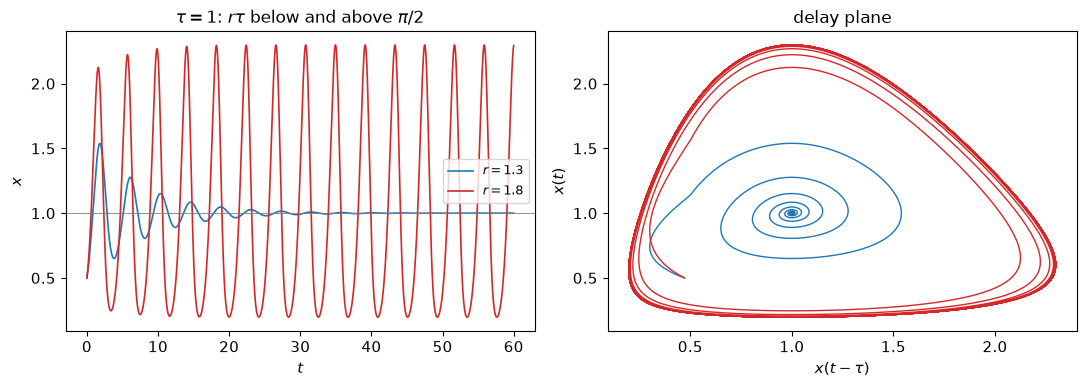

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for r, col in ((1.3, "tab:blue"), (1.8, "tab:red")):
    tr = m.run(keep=False, r=r, total=60)
    ax1.plot(tr.t, tr["x"], color=col, lw=1.2, label=f"$r = {r}$")
    ax2.plot(tr["xlag"], tr["x"], color=col, lw=1)
ax1.axhline(1, color="tab:gray", lw=0.6)
ax1.set(xlabel="$t$", ylabel="$x$", title=r"$\tau = 1$: $r\tau$ below and above $\pi/2$")
ax1.legend()
ax2.set(xlabel=r"$x(t - \tau)$", ylabel="$x(t)$", title="delay plane")
fig.tight_layout()
fig.savefig(FIG / "time_series.png")

### Amplitude at long times, and the onset

The peak-to-peak amplitude after transients, against $r$ (at $\tau = 1$) and
against $\tau$ (at $r = 1$). Near a supercritical Hopf point the squared
amplitude grows linearly with the distance past it,

$$
A^2 \approx k\,(\mu - \mu_c),
$$

so `onset` fits $A^2$ at a few values just above onset and extrapolates to
zero. Close to onset the oscillation settles slowly, so those runs are long.

onset: r = 1.57059 at tau = 1, tau = 1.57059 at r = 1 (pi/2 = 1.57080)


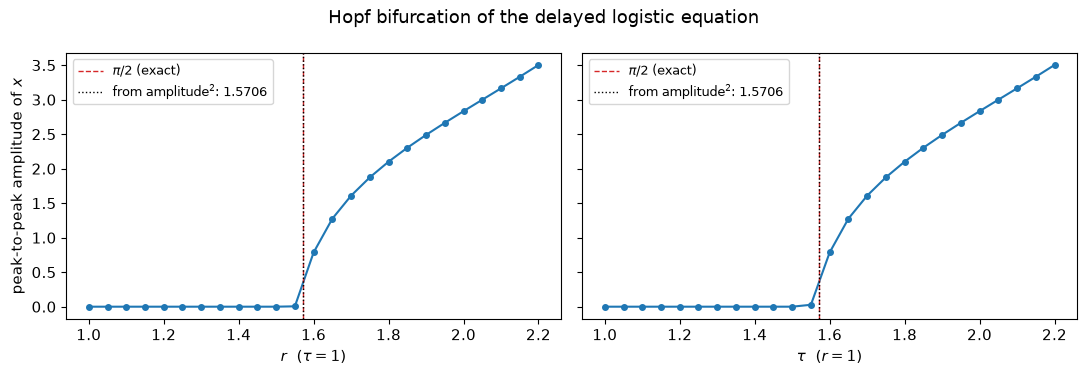

In [6]:
def amp(r, tau, total=600, trans=500):
    return np.ptp(m.run(keep=False, r=r, tau=tau, total=total, trans=trans)["x"])


def onset(values, f):
    a2 = np.array([f(v)**2 for v in values])
    slope, icept = np.polyfit(values, a2, 1)
    return -icept / slope


R = np.linspace(1.0, 2.2, 25)
T = np.linspace(1.0, 2.2, 25)
amp_r = [amp(r, 1) for r in R]
amp_t = [amp(1, t) for t in T]
near = np.linspace(1.58, 1.60, 5)
r_c = onset(near, lambda r: amp(r, 1, 1500, 1300))
tau_c = onset(near, lambda t: amp(1, t, 1500, 1300))
print(f"onset: r = {r_c:.5f} at tau = 1, tau = {tau_c:.5f} at r = 1 (pi/2 = {np.pi / 2:.5f})")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, v, a, c, lab in ((axs[0], R, amp_r, r_c, r"$r$  ($\tau = 1$)"),
                         (axs[1], T, amp_t, tau_c, r"$\tau$  ($r = 1$)")):
    ax.plot(v, a, "o-", ms=4)
    ax.axvline(np.pi / 2, color="tab:red", ls="--", lw=1, label=r"$\pi/2$ (exact)")
    ax.axvline(c, color="k", ls=":", lw=1, label=f"from amplitude$^2$: {c:.4f}")
    ax.set(xlabel=lab)
    ax.legend()
axs[0].set_ylabel("peak-to-peak amplitude of $x$")
fig.suptitle("Hopf bifurcation of the delayed logistic equation")
fig.tight_layout()
fig.savefig(FIG / "amplitude.png")

### Period near onset, and the $r\tau$ scaling

The period just above onset ($r\tau = 1.58$), and at $r\tau = 1.8$ for
$(r, \tau) = (1.8, 1)$ and $(0.9, 2)$. Rescaling time by $\tau$ turns a run
with $\tau = 2$ into one with $\tau = 1$ and step $dt/\tau$, so the $\tau = 2$
run gets the step $2\,dt$: the same number of steps per delay (with equal
$dt$, XPP's $dt/2$ lag would make the effective $r\tau$ differ slightly).

In [7]:
P_on = period(m.run(keep=False, r=1.58, tau=1, total=1500, trans=1300))
P1 = m.run(keep=False, r=1.8, tau=1, total=300, trans=200)
P2 = m.run(keep=False, r=0.9, tau=2, dt=0.004, total=600, trans=400)
print(f"period at r tau = 1.58: {P_on:.4f};  r tau = 1.8: period {period(P1):.4f} (tau = 1), "
      f"{period(P2):.4f} (tau = 2)")

period at r tau = 1.58: 4.0063;  r tau = 1.8: period 4.1835 (tau = 1), 8.3670 (tau = 2)


### Checks

* With $x = 1 + u$ the linearisation is $\dot u = -r\,u(t - \tau)$. Putting
  $u = e^{i\omega t}$ gives $i\omega = -r\,e^{-i\omega\tau}$, so
  $\cos\omega\tau = 0$ and $\omega = r$: the first crossing has
  $\omega\tau = \pi/2$, i.e.

$$
r\tau = \frac{\pi}{2}, \qquad \text{period at onset } \frac{2\pi}{\omega} = 4\tau .
$$

  The onset is checked in $r$ (at $\tau = 1$) and in $\tau$ (at $r = 1$), and
  the period just above onset is still close to 4.
* With $s = t/\tau$ the equation becomes
  $dx/ds = (r\tau)\,x\,\bigl(1 - x(s - 1)\bigr)$, so only $r\tau$ matters: the
  same amplitude for $(1.8, 1)$ and $(0.9, 2)$, and a period proportional to
  $\tau$ (ratio exactly 2).

In [8]:
check("onset in r at tau = 1 (exact pi/2)", r_c, np.pi / 2, 0.01)
check("onset in tau at r = 1 (exact pi/2)", tau_c, np.pi / 2, 0.01)
check("period just above onset, tau = 1 (exact at onset: 4)", P_on, 4.0, 0.05)
check("same amplitude for (r, tau) = (1.8, 1) and (0.9, 2)", np.ptp(P2["x"]), np.ptp(P1["x"]), 1e-3)
check("period ratio for tau = 2 and tau = 1 (exact 2)", period(P2) / period(P1), 2.0, 1e-3)
checks_done()

  ok   onset in r at tau = 1 (exact pi/2): 1.57059 (expected 1.5708)
  ok   onset in tau at r = 1 (exact pi/2): 1.57059 (expected 1.5708)
  ok   period just above onset, tau = 1 (exact at onset: 4): 4.00633 (expected 4)
  ok   same amplitude for (r, tau) = (1.8, 1) and (0.9, 2): 2.10128 (expected 2.10128)
  ok   period ratio for tau = 2 and tau = 1 (exact 2): 2 (expected 2)

29_delayed-logistic: 5/5 checks passed


<a id="mackey-glass"></a>
## 30. Mackey–Glass: chaos from a delay

A model of blood-cell production: cells are made at a rate set by the
population $\tau$ time units ago and die at rate $g$,

$$
\dot x(t) = \frac{b\,x(t - \tau)}{1 + x(t - \tau)^{p}} - g\,x(t),
$$

with $b = 0.2$, $g = 0.1$, $p = 10$ and the constant history $x = 0.5$ for
$t \le 0$. For small $\tau$ the population settles to a steady level; as
$\tau$ grows it oscillates, the oscillation doubles its period, and at
$\tau = 17$ the dynamics are chaotic, although the equation has only one
variable.

We check the steady level, plot the maxima of $x$ against $\tau$, draw the
delay embedding at four values of $\tau$, and locate the loss of stability of
the steady level. Everything here comes from simulation (AUTO on this equation
is in 06b, model 37).

In [9]:
section("30_mackey-glass")

### The model

XPP sizes its store of past values from $dt$ and the maximal delay when the
model loads, and pyxpp does not resize it when $dt$ is changed later. So the
model gets the smallest step used ($dt = 0.01$, for the onset), and the sweeps
run with the larger step `DT` $= 0.1$, which is safe (a smaller $dt$ than at
load time is not). `maxima(x)` returns the local maxima of a time series.

In [10]:
b, g, pw = 0.2, 0.1, 10
mb = (ModelBuilder("mackey_glass")
      .comment("Mackey-Glass equation")
      .ode("x", "b*delay(x,tau)/(1+delay(x,tau)^pw)-g*x")
      .aux("xlag", "delay(x,tau)")
      .parameter(b=b, g=g, pw=pw, tau=17)
      .initial(x=0.5)
      .option(total=1000, dt=0.01, delay=40))
DT = 0.1
print(mb.render())
m = mb.load(ODE)


def maxima(x):
    return x[np.where((x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:]))[0] + 1]

# Mackey-Glass equation
x'=b*delay(x,tau)/(1+delay(x,tau)^pw)-g*x
aux xlag=delay(x,tau)
par b=0.2,g=0.1,pw=10,tau=17
init x=0.5
@ total=1000,dt=0.01,delay=40
done



### The steady level at small $\tau$

The value of $x$ at $t = 2000$ for $\tau = 1, 2, 4$.

In [11]:
x_end = {tau: m.run(keep=False, tau=tau, dt=DT, total=2000)["x"][-1] for tau in (1, 2, 4)}
print("x at t = 2000:", {k: round(v, 7) for k, v in x_end.items()})

x at t = 2000: {1: np.float64(1.0), 2: np.float64(1.0), 4: np.float64(1.0)}


### Maxima of $x$ against $\tau$

211 values of $\tau$ between 4 and 25; for each, the maxima of $x$ over 1000
time units after a transient of 2000. One maximum per $\tau$ is a simple
oscillation, two a period-2 orbit, and a smear chaos.

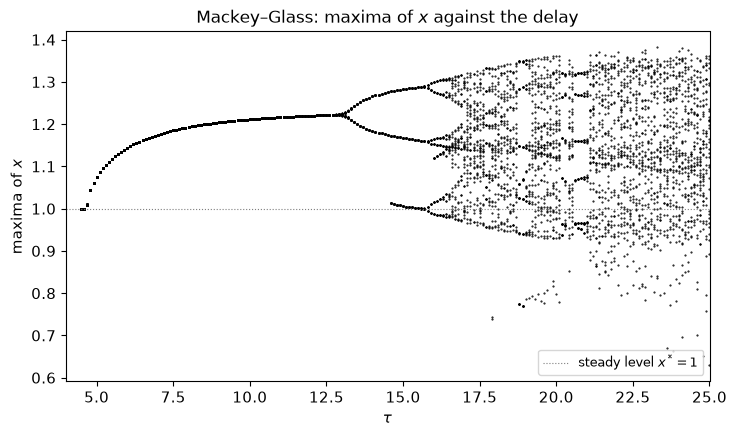

In [12]:
TAU, M = [], []
for tau in np.linspace(4, 25, 211):
    mx = maxima(m.run(keep=False, tau=tau, dt=DT, total=3000, trans=2000)["x"])
    TAU += [tau] * len(mx)
    M += list(mx)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(TAU, M, "k.", ms=1)
ax.axhline(1, color="tab:gray", lw=0.8, ls=":", label="steady level $x^* = 1$")
ax.set(xlim=(4, 25), xlabel=r"$\tau$", ylabel="maxima of $x$",
       title="Mackey–Glass: maxima of $x$ against the delay")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "maxima_vs_tau.png")

### Delay embedding

Plotting $x(t)$ against $x(t - \tau)$ unfolds the attractor in the plane:
period 1, period 2, period 4 and chaos.

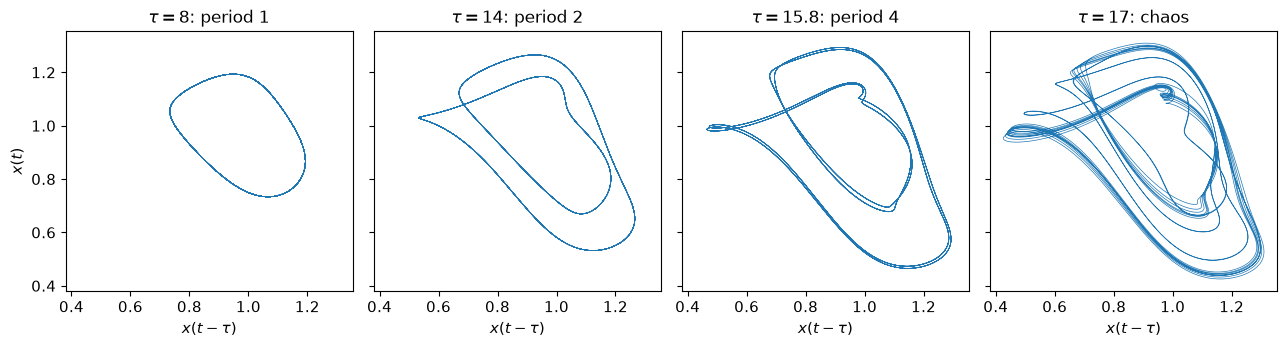

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.6), sharex=True, sharey=True)
for ax, tau, lab in zip(axs, (8, 14, 15.8, 17), ("period 1", "period 2", "period 4", "chaos")):
    tr = m.run(keep=False, tau=tau, dt=DT, total=3000, trans=2000)
    ax.plot(tr["xlag"], tr["x"], lw=0.5)
    ax.set(title=rf"$\tau = {tau}$: {lab}", xlabel=r"$x(t - \tau)$")
axs[0].set_ylabel("$x(t)$")
fig.tight_layout()
fig.savefig(FIG / "embedding.png")

### Loss of stability of the steady level

As in section 29, the squared amplitude grows linearly just past a
supercritical Hopf point: fit and extrapolate to zero. A finer step here: the
$dt/2$ lag of delayed values shifts the onset by about $dt/2$ (0.005 with
$dt = 0.01$). We also measure the period at $\tau = 4.75$, just past onset.

In [14]:
near = np.linspace(4.75, 4.95, 5)
a2 = [np.ptp(m.run(keep=False, tau=t, dt=0.01, total=4000, trans=3800)["x"])**2 for t in near]
slope, icept = np.polyfit(near, a2, 1)
tau_c = -icept / slope
tr = m.run(keep=False, tau=4.75, dt=0.01, total=4000, trans=3000)
x, t = tr["x"] - 1, tr.t
up = t[1:][(x[:-1] < 0) & (x[1:] >= 0)]
P_on = np.diff(up).mean()
print(f"steady level loses stability at tau = {tau_c:.4f}; period at tau = 4.75: {P_on:.3f}")

steady level loses stability at tau = 4.7070; period at tau = 4.75: 16.351


### Checks

* The steady level: $\dot x = 0$ with $x(t - \tau) = x$ gives
  $b/(1 + x^p) = g$, so

$$
x^* = \Bigl(\frac{b}{g} - 1\Bigr)^{1/p} = 1,
$$

  checked at $\tau = 1, 2, 4$.
* Linearising about $x^*$: $\dot u = -g\,u + f'\,u(t - \tau)$ with

$$
f' = \frac{b\,\bigl(1 - (p - 1)\,(x^*)^p\bigr)}{\bigl(1 + (x^*)^p\bigr)^2} = -0.4 .
$$

  Putting $u = e^{i\omega t}$: $i\omega = -g + f' e^{-i\omega\tau}$, so
  $\cos\omega\tau = g/f' = -1/4$ and $\omega = \sqrt{f'^2 - g^2}$. The
  steady level loses stability at

$$
\tau_c = \frac{\arccos(g/f')}{\omega} \approx 4.71,
$$

  where the period is $2\pi/\omega \approx 16.2$.

In [15]:
x_star = (b / g - 1) ** (1 / pw)
for tau, xe in x_end.items():
    check(f"steady level at tau = {tau} (exact)", xe, x_star, 1e-6)
fp = b * (1 - (pw - 1) * x_star**pw) / (1 + x_star**pw) ** 2
w = np.sqrt(fp**2 - g**2)
tau_exact = np.arccos(g / fp) / w
check("onset of oscillation, tau_c (exact)", tau_c, tau_exact, 0.02)
check("period just past onset (exact at onset: 2 pi/w)", P_on, 2 * np.pi / w, 0.2)
checks_done()

  ok   steady level at tau = 1 (exact): 1 (expected 1)
  ok   steady level at tau = 2 (exact): 1 (expected 1)
  ok   steady level at tau = 4 (exact): 1 (expected 1)
  ok   onset of oscillation, tau_c (exact): 4.70696 (expected 4.7082)
  ok   period just past onset (exact at onset: 2 pi/w): 16.3507 (expected 16.2231)

30_mackey-glass: 5/5 checks passed


<a id="distributed-delay-volterra"></a>
## 31. Distributed delay: a Volterra integral equation

Logistic growth regulated by the population's whole past, weighted by a gamma
kernel with mean delay $2\tau$:

$$
\dot x(t) = r\,x(t)\left(1 - \int_0^t K(t - s)\,x(s)\,ds\right),
\qquad K(u) = \frac{u}{\tau^2}\,e^{-u/\tau},
$$

with $r = 1$ and $x(0) = 0.5$. XPP writes the integral as `int{K#x}` and
solves the equation by its Volterra method. The same kernel can be removed by
the *linear chain trick*:

$$
\dot y_1 = \frac{x - y_1}{\tau}, \qquad \dot y_2 = \frac{y_1 - y_2}{\tau}
\quad\Longrightarrow\quad y_2(t) = \int_0^t K(t - s)\,x(s)\,ds,
$$

so the equation is also a three-variable ODE, $\dot x = r\,x\,(1 - y_2)$. The
equilibrium $x = 1$ loses stability at $r\tau = 2$.

We compare the two solutions (and see their difference shrink like $dt^2$),
then sweep $\tau$ at $r = 1$ and find the onset of oscillation from the
amplitude.

In [16]:
section("31_distributed-delay-volterra")

### The two models

XPP tabulates the kernel $K$ on the time grid when the model loads, and pyxpp
does not recompute that table when $\tau$ or $dt$ is changed later. So
`volterra(tau, dt)` builds the Volterra model for given values, and each run
with another $\tau$ or $dt$ gets its own freshly loaded model (`load(text=...)`).
$\tau$ is passed as a plain float, since the builder would write a numpy float
as `np.float64(...)`. `vmaxpts` keeps 50 time units of past. The chain ODE
starts with $y_1 = y_2 = 0$, since the integral over $[0, t]$ starts at 0; it
is written to its own file next to the Volterra model.

In [17]:
from pyxpp import load


def volterra(tau, dt=0.05):
    return (ModelBuilder("distributed_delay")
            .comment("logistic growth with a gamma-distributed delay")
            .ode("x", "r*x*(1-int{t*exp(-t/tau)/tau^2#x})")
            .parameter(r=1, tau=float(tau))
            .initial(x=0.5)
            .option(total=200, dt=dt, vmaxpts=round(50 / dt)))


mb = volterra(2.5)
print(mb.render())
m = mb.load(ODE)

chain = (ModelBuilder("distributed_delay_chain")
         .comment("the same equation by the linear chain trick: y2 = int K x")
         .ode("x", "r*x*(1-y2)")
         .ode("y1", "(x-y1)/tau")
         .ode("y2", "(y1-y2)/tau")
         .parameter(r=1, tau=2.5)
         .initial(x=0.5, y1=0, y2=0)
         .option(total=200, dt=0.05)
         .load(ODE.with_name(f"{NAME}_chain.ode")))

# logistic growth with a gamma-distributed delay
x'=r*x*(1-int{t*exp(-t/tau)/tau^2#x})
par r=1,tau=2.5
init x=0.5
@ total=200,dt=0.05,vmaxpts=1000
done



### Volterra against the chain ODE

Damped ($\tau = 1.5$) and oscillating ($\tau = 2.5$) solutions, each with
$dt = 0.05$ and $dt = 0.025$; the chain ODE runs on the same time grid. The
upper panel overlays the two solutions, the lower one shows their difference.

tau = 1.5: largest difference 1.75e-03 (dt = 0.05), 4.38e-04 (dt = 0.025)


tau = 2.5: largest difference 2.93e-02 (dt = 0.05), 7.31e-03 (dt = 0.025)


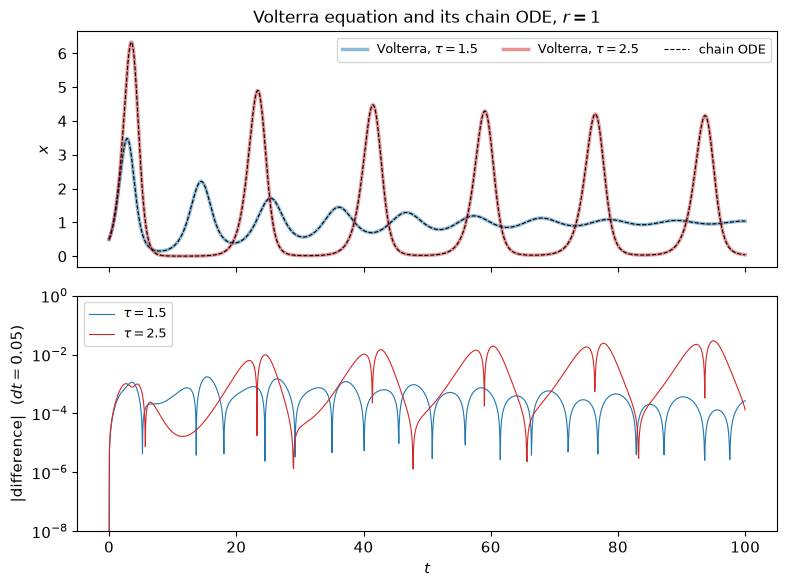

In [18]:
fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
diff = {}
for tau, col in ((1.5, "tab:blue"), (2.5, "tab:red")):
    for dt in (0.05, 0.025):
        ode = chain.run(keep=False, tau=tau, dt=dt, total=100)
        mv = m if (tau, dt) == (2.5, 0.05) else load(text=volterra(tau, dt).render())
        vol = mv.run(keep=False, total=100)
        n = min(len(vol), len(ode))
        diff[tau, dt] = np.abs(vol["x"][:n] - ode["x"][:n]).max()
        if mv is not m:
            mv.close()
        if dt == 0.05:
            axs[0].plot(vol.t, vol["x"], color=col, lw=2.5, alpha=0.5, label=rf"Volterra, $\tau = {tau}$")
            axs[1].semilogy(vol.t, np.abs(vol["x"] - ode["x"]) + 1e-9, color=col, lw=0.8,
                            label=rf"$\tau = {tau}$")
            axs[0].plot(ode.t, ode["x"], "k--", lw=0.8)
    print(f"tau = {tau}: largest difference {diff[tau, 0.05]:.2e} (dt = 0.05), "
          f"{diff[tau, 0.025]:.2e} (dt = 0.025)")
axs[0].plot([], [], "k--", lw=0.8, label="chain ODE")
axs[0].set(ylabel="$x$", title="Volterra equation and its chain ODE, $r = 1$")
axs[0].legend(ncol=3)
axs[1].set(xlabel="$t$", ylabel=r"$|$difference$|$  ($dt = 0.05$)", ylim=(1e-8, 1))
axs[1].legend()
fig.tight_layout()
fig.savefig(FIG / "volterra_vs_chain.png")

### Onset of oscillation in $\tau$ at $r = 1$

The peak-to-peak amplitude after transients for both forms, on a grid of
$\tau$; then, for each form, the squared amplitude just above onset is
extrapolated to zero (as in section 29). Finally the period of the chain ODE
at $\tau = 2.02$.

onset in tau: {'Volterra': np.float64(1.9981), 'chain ODE': np.float64(1.9984)} ; period at tau = 2.02: 12.743


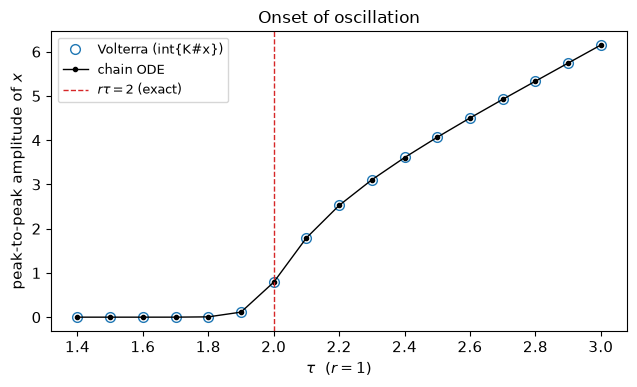

In [19]:
def amp_volterra(tau, total=600, trans=500):
    mv = load(text=volterra(tau).render())
    a = np.ptp(mv.run(total=total, trans=trans)["x"])
    mv.close()
    return a


def amp_chain(tau, total=600, trans=500):
    return np.ptp(chain.run(keep=False, tau=tau, total=total, trans=trans)["x"])


TAU = np.linspace(1.4, 3.0, 17)
A_vol = [amp_volterra(t) for t in TAU]
A_ode = [amp_chain(t) for t in TAU]
near = np.linspace(2.02, 2.10, 5)
onsets = {}
for nm, f in (("Volterra", amp_volterra), ("chain ODE", amp_chain)):
    a2 = [f(t, 1500, 1300)**2 for t in near]
    slope, icept = np.polyfit(near, a2, 1)
    onsets[nm] = -icept / slope
tr = chain.run(keep=False, tau=2.02, total=1500, trans=1000)
x, t = tr["x"] - 1, tr.t
P_on = np.diff(t[1:][(x[:-1] < 0) & (x[1:] >= 0)]).mean()
print("onset in tau:", {k: round(v, 4) for k, v in onsets.items()}, f"; period at tau = 2.02: {P_on:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(TAU, A_vol, "o", ms=7, mfc="none", label="Volterra (int{K#x})")
ax.plot(TAU, A_ode, "k.-", lw=1, label="chain ODE")
ax.axvline(2, color="tab:red", ls="--", lw=1, label=r"$r\tau = 2$ (exact)")
ax.set(xlabel=r"$\tau$  ($r = 1$)", ylabel="peak-to-peak amplitude of $x$", title="Onset of oscillation")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "amplitude.png")

### Checks

* Both are second-order methods solving the same equation, so their
  difference should drop by $2^2 = 4$ when $dt$ is halved (for $\tau = 1.5$ and
  $2.5$).
* About $x = 1$ the chain gives $\dot u = -r v_2$,
  $\dot v_1 = (u - v_1)/\tau$, $\dot v_2 = (v_1 - v_2)/\tau$, so the
  characteristic equation is

$$
\lambda\,(1 + \lambda\tau)^2 = -r .
$$

  With $\lambda = i\omega$, the imaginary part
  $\omega\,(1 - \omega^2\tau^2) = 0$ gives $\omega\tau = 1$, and the real part
  $-2\omega^2\tau = -r$ gives $r\tau = 2$: at $r = 1$ the onset is at
  $\tau = 2$ (from both forms), with period $2\pi\tau = 4\pi$ at onset.

In [20]:
for tau in (1.5, 2.5):
    check(f"Volterra - ODE difference ratio, dt halved, tau = {tau} (2nd order: 4)",
          diff[tau, 0.05] / diff[tau, 0.025], 4.0, 0.4)
check("onset tau from the Volterra equation (exact 2)", onsets["Volterra"], 2.0, 0.02)
check("onset tau from the chain ODE (exact 2)", onsets["chain ODE"], 2.0, 0.02)
check("period just above onset (exact at onset: 2 pi tau = 4 pi)", P_on, 4 * np.pi, 0.2)
checks_done()

  ok   Volterra - ODE difference ratio, dt halved, tau = 1.5 (2nd order: 4): 4.0019 (expected 4)
  ok   Volterra - ODE difference ratio, dt halved, tau = 2.5 (2nd order: 4): 4.00261 (expected 4)
  ok   onset tau from the Volterra equation (exact 2): 1.99807 (expected 2)
  ok   onset tau from the chain ODE (exact 2): 1.99845 (expected 2)
  ok   period just above onset (exact at onset: 2 pi tau = 4 pi): 12.7434 (expected 12.5664)

31_distributed-delay-volterra: 5/5 checks passed


## Summary

All checks of this notebook:

In [21]:
for name, r in results.items():
    print(f"{name:40s} {sum(r):3d}/{len(r)}")
n_ok = sum(sum(r) for r in results.values())
n = sum(len(r) for r in results.values())
print(f"\n{n_ok}/{n} checks passed")

29_delayed-logistic                        5/5
30_mackey-glass                            5/5
31_distributed-delay-volterra              5/5

15/15 checks passed
